### Langgraph first Mini Project

### Linear Graph Flow 

##### Typed Dict helps to tell us what type of data is to be inserted

In [41]:
from langgraph.graph import StateGraph ,START,END
from typing import TypedDict, Any

In [42]:
## Define a simple state graph for BMI calculation
class BMIGraph(TypedDict):
    weight: float
    height: float
    bmi: float  
    category: str

In [43]:
def calculate_bmi(state: BMIGraph) -> BMIGraph:
    weight=state["weight"]
    height=state["height"]
    bmi = weight / (height ** 2)
    state["bmi"] =round(bmi, 2)
    return state
   

In [48]:
def label_BMI(state: BMIGraph) -> BMIGraph:
    bmi = state["bmi"]
    if bmi < 18.5:
        state["category"] = "Underweight"
    elif 18.5 <= bmi < 24.9:
        state["category"] = "Normal weight"
    elif 25 <= bmi < 29.9:
        state["category"] = "Overweight"
    else:
        state["category"] = "Obesity"
    return state

In [49]:
##Define the state graph
graph = StateGraph(BMIGraph)

##add the nodes for the graph 
graph.add_node("calculate_bmi",calculate_bmi )
graph.add_node('Label_BMI',label_BMI)

##add edges for the graph
graph.add_edge(START, "calculate_bmi")
graph.add_edge("calculate_bmi", 'Label_BMI')
graph.add_edge('Label_BMI', END)


##compute the BMI based on the weight and height
workflow = graph.compile()

In [50]:
##Execute the workflow with the input values for weight and height
initial_state = {"weight": 70, "height": 5}

final_state = workflow.invoke(initial_state)
print(final_state)  # Output: {'weight': 70, 'height': 5, 'bmi': 2.8}

{'weight': 70, 'height': 5, 'bmi': 2.8, 'category': 'Underweight'}


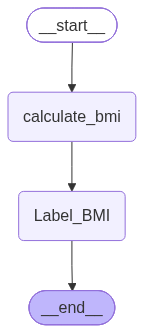

In [51]:
from IPython.display import Image, display

Image(workflow.get_graph().draw_mermaid_png())
  # Output: {'weight': 70, 'height': 5, 'bmi': 2.8}